# Лабораторна робота №1

**Предмет аналізу** - замовлення інтернет-магазину зі спеціальною пропозицією (с.п.). Якщо в замовленні є товар за с.п., доставка безкоштовна, інакше вона коштує 20 грн. Такий товар можна повернути без витрат. Є припущення, що частина клієнтів кладе в кошик дешевий акційний товар лише заради безкоштовної доставки й одразу його повертає. Мета - описати дані та оцінити масштаб цього явища.

У `data.csv` один рядок відповідає одному замовленню:
- `total` - загальна сума, $\xi_i + \eta_i$;
- `special_proposition` - ціна товару за с.п., $\eta_i$;
- `return` - ознака повернення товару за с.п., $p_i \in \{0,1\}$.

Ціна решти товарів $\xi_i$ дорівнює `total` $-$ `special_proposition`. Замовлення вважаємо незалежними й однаково розподіленими.

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv("data.csv", index_col=0)
N = len(orders)

sp = orders["special_proposition"].to_numpy()
other = (orders["total"] - orders["special_proposition"]).to_numpy()
back = orders["return"].to_numpy().astype(bool)

print("кількість замовлень:", N)
print("пропущених значень:", orders.isna().sum().sum())
print("найменше значення xi:", round(other.min(), 4))
print("найменше значення eta:", round(sp.min(), 4))
orders.head()

кількість замовлень: 1000
пропущених значень: 0
найменше значення xi: 0.1016
найменше значення eta: 0.005


,total,return,special_proposition
0,88.678970,False,9.141027
1,104.085105,True,8.569498
2,136.883561,False,50.300859
3,122.467426,False,44.532713
4,145.383339,True,0.075905


Пропусків немає, всі $\xi_i$ та $\eta_i$ додатні, тож дані придатні для аналізу.

**Як будуємо довірчі інтервали.** У розділах 1-3 оцінка $\hat\theta$ така, що $(\hat\theta-\theta)/SE$ за ЦГТ наближено нормальна. Якщо $SE$ містить невідомий параметр, підставляємо його консистентну оцінку (теорема Слуцького). Інтервал має вигляд $\hat\theta \pm z\cdot SE$, де для рівня 0.95 береться $z = 1.96$, для рівня 0.99 - $z = 2.576$.

In [45]:
Z = {0.95: 1.96, 0.99: 2.576}

def interval(estimate, se, level):
    return estimate - Z[level] * se, estimate + Z[level] * se

def show_intervals(estimate, se):
    for level in Z:
        lo, hi = interval(estimate, se, level)
        print(f"рівень {level}: від {lo:.4f} до {hi:.4f}")

## 1. Скільки товарів повертають

Кожне $p_i$ - це випробування Бернуллі з невідомою ймовірністю повернення $p$: $Ep_i = p$, $Dp_i = p(1-p)$. Природна оцінка - частка повернених замовлень
$$\hat p = \frac1N\sum_{i=1}^N p_i .$$
Вона незміщена, бо $E\hat p = p$. Її дисперсія $p(1-p)/N$ прямує до нуля, тому за нерівністю Чебишова оцінка консистентна. З ЦГТ, замінивши $p$ на $\hat p$ у знаменнику, отримуємо $SE=\sqrt{\hat p(1-\hat p)/N}$.

In [46]:
p_est = back.mean()
se_p = np.sqrt(p_est * (1 - p_est) / N)

print("повернено замовлень:", back.sum())
print("p =", p_est, "   SE =", round(se_p, 4))
show_intervals(p_est, se_p)

повернено замовлень: 278
p = 0.278    SE = 0.0142
рівень 0.95: від 0.2502 до 0.3058
рівень 0.99: від 0.2415 до 0.3145


**Результат.** $\hat p = 0.278$: повертається близько 28% акційних товарів. Довірчий інтервал рівня 0.95 - $[0.250;\ 0.306]$, рівня 0.99 - $[0.242;\ 0.315]$ (більша надійність дає ширший інтервал). Рівень 0.95 означає, що при багатократному повторенні вибірки з 1000 замовлень близько 95% побудованих таким способом інтервалів накриють справжнє $p$.

## 2. Ціна товарів за с.п.

### 2.1 Середнє та довірчі інтервали

Оцінка середнього - вибіркове середнє $\bar\eta$. Воно незміщене й консистентне. За ЦГТ $\sqrt N(\bar\eta-\mu)/\sigma\to N(0,1)$; невідоме $\sigma$ замінюємо виправленим вибірковим відхиленням $S=\sqrt{\frac1{N-1}\sum(\eta_i-\bar\eta)^2}$ (в `numpy` це `ddof=1`), тому $SE=S/\sqrt N$.

In [47]:
mean_sp = sp.mean()
se_sp = sp.std(ddof=1) / np.sqrt(N)

print("середнє =", round(mean_sp, 4), "   SE =", round(se_sp, 4))
show_intervals(mean_sp, se_sp)

середнє = 31.3233    SE = 1.0008
рівень 0.95: від 29.3618 до 33.2848
рівень 0.99: від 28.7453 до 33.9013


### 2.2 Гістограма та емпірична функція розподілу

Надалі припускаємо $\eta_i\sim Exp(\lambda k)$. Емпірична функція розподілу $F_N(x)=\frac1N\#\{i:\eta_i\le x\}$ будується так: упорядковуємо вибірку, $i$-й за величиною елемент має значення $i/N$.

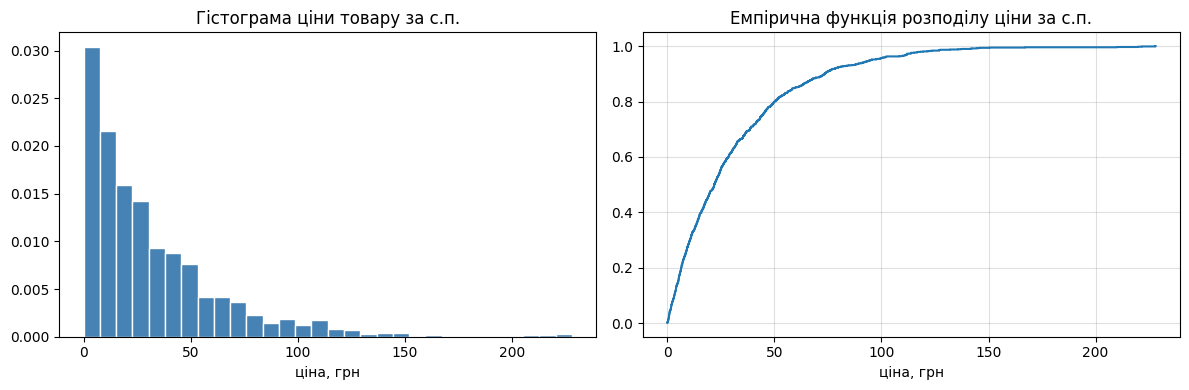

In [48]:
def ecdf(sample):
    xs = np.sort(sample)
    ys = np.arange(1, len(xs) + 1) / len(xs)
    return xs, ys

xs_sp, ys_sp = ecdf(sp)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(sp, bins=30, density=True, color="steelblue", edgecolor="white")
axes[0].set_title("Гістограма ціни товару за с.п.")
axes[0].set_xlabel("ціна, грн")

axes[1].step(xs_sp, ys_sp, where="post")
axes[1].set_title("Емпірична функція розподілу ціни за с.п.")
axes[1].set_xlabel("ціна, грн")
axes[1].grid(alpha=0.4)

plt.tight_layout()
plt.show()

### 2.3 Оцінка $\lambda k$

У розподілі $\eta$ параметри $\lambda$ і $k$ присутні тільки як добуток, тому оцінюємо одну величину $\theta=\lambda k$.

*Метод моментів.* Для $Exp(\theta)$ маємо $E\eta=1/\theta$. Прирівнюємо до вибіркового середнього: $1/\theta=\bar\eta$, звідки $\hat\theta=1/\bar\eta$.

*Метод максимальної правдоподібності.* Логарифмічна функція правдоподібності $\ell(\theta)=N\ln\theta-\theta\sum\eta_i$. Похідна $N/\theta-\sum\eta_i$ дорівнює нулю при $\theta=1/\bar\eta$, друга похідна $-N/\theta^2<0$, тож це максимум. Обидва методи дають однакову оцінку.

### 2.4 Теоретична функція розподілу

$F(x)=1-e^{-\hat\theta x}$ для $x\ge0$.

lambda*k = 0.03193


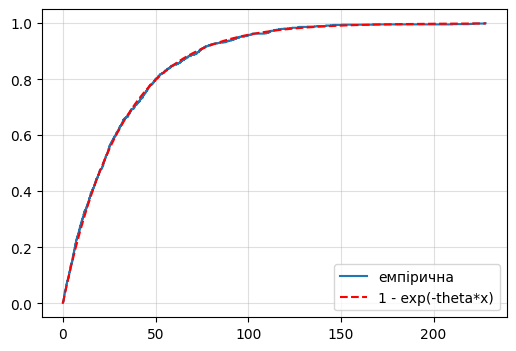

In [49]:
theta_hat = 1 / mean_sp
print("lambda*k =", round(theta_hat, 5))

grid = np.linspace(0, sp.max(), 300)
plt.figure(figsize=(6, 4))
plt.step(xs_sp, ys_sp, where="post", label="емпірична")
plt.plot(grid, 1 - np.exp(-theta_hat * grid), "r--", label="1 - exp(-theta*x)")
plt.legend()
plt.grid(alpha=0.4)
plt.show()

**Результат.** Середня ціна товару за с.п. - близько 31.32 грн; інтервал рівня 0.95: $[29.36;\ 33.28]$, рівня 0.99: $[28.75;\ 33.90]$. Оцінка $\widehat{\lambda k}\approx0.0319$. Теоретична крива майже накладається на емпіричну, отже експоненційна модель для $\eta$ прийнятна.

## 3. Решта товарів у замовленні

### 3.1 Середнє та довірчі інтервали

Усе так само, як у п. 2.1, лише для $\xi_i$.

In [50]:
mean_other = other.mean()
se_other = other.std(ddof=1) / np.sqrt(N)

print("середнє =", round(mean_other, 4), "   SE =", round(se_other, 4))
show_intervals(mean_other, se_other)

середнє = 99.1665    SE = 3.0887
рівень 0.95: від 93.1127 до 105.2204
рівень 0.99: від 91.2100 до 107.1231


Інтервали ширші, ніж для $\eta$: ціни решти товарів більш розкидані.

### 3.2 Оцінка $\lambda$, гістограма та функція розподілу

Припускаємо $\xi_i\sim Exp(\lambda)$ з тим самим $\lambda$. Як у п. 2.3, обидва методи дають $\hat\lambda=1/\bar\xi$.

lambda = 0.01008


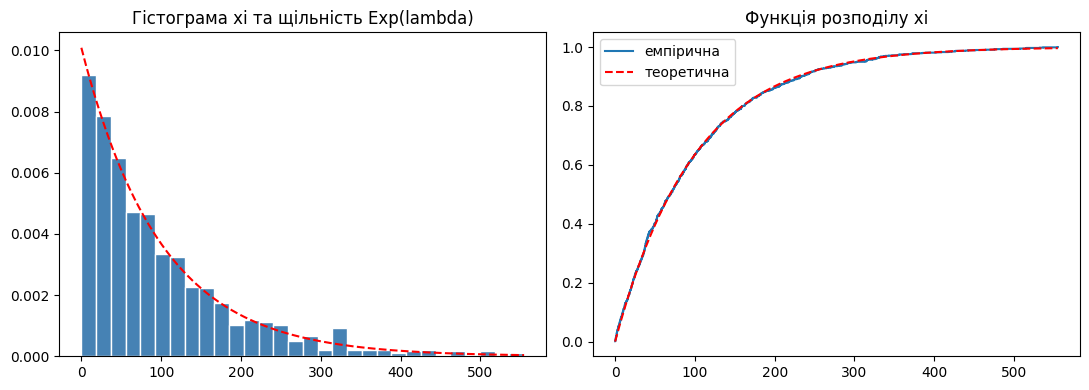

In [51]:
lam_hat = 1 / mean_other
print("lambda =", round(lam_hat, 5))

xs_o, ys_o = ecdf(other)
grid = np.linspace(0, other.max(), 300)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(other, bins=30, density=True, color="steelblue", edgecolor="white")
axes[0].plot(grid, lam_hat*np.exp(-lam_hat*grid), "r--")
axes[0].set_title("Гістограма xi та щільність Exp(lambda)")
axes[1].step(xs_o, ys_o, where="post", label="емпірична")
axes[1].plot(grid, 1 - np.exp(-lam_hat * grid), "r--", label="теоретична")
axes[1].set_title("Функція розподілу xi")
axes[1].legend()
plt.tight_layout()
plt.show()

### 3.3 Властивості оцінки $\hat\lambda=1/\bar\xi$

**Консистентність.** Середнє $\bar\xi$ має сподівання $1/\lambda$ і дисперсію $\frac1{N\lambda^2}\to0$, тому за законом великих чисел $\bar\xi\xrightarrow{P}1/\lambda$. Функція $x\mapsto1/x$ неперервна в точці $1/\lambda>0$, отже $\hat\lambda\xrightarrow{P}\lambda$. Оцінка консистентна.

**Зміщеність.** Функція $g(x)=1/x$ строго опукла на $(0,\infty)$, а $\bar\xi$ - невироджена випадкова величина. За нерівністю Єнсена
$$E\hat\lambda=E\,g(\bar\xi)>g(E\bar\xi)=\lambda .$$
Тож $\hat\lambda$ зміщена, вона в середньому завищує $\lambda$.

**Розмір зміщення.** Сума $\sum\xi_i$ має розподіл Гамма$(N,\lambda)$, для якого $E\frac1{\sum\xi_i}=\frac{\lambda}{N-1}$. Тому $E\hat\lambda=\frac{N}{N-1}\lambda$, зміщення дорівнює $\frac{\lambda}{N-1}$, тобто близько 0.1% від $\lambda$ при $N=1000$. Оцінка $\frac{N-1}{N}\hat\lambda$ уже незміщена.

### 3.4 (*) Оцінка $k$

З $E\xi=1/\lambda$ та $E\eta=1/(\lambda k)$ маємо $k=E\xi/E\eta$. Підставляємо вибіркові середні:
$$\hat k=\frac{\bar\xi}{\bar\eta}.$$

**Консистентність.** $\bar\xi\xrightarrow{P}1/\lambda$, $\bar\eta\xrightarrow{P}1/(\lambda k)>0$, а відношення неперервне за знаменника, відмінного від нуля, тому $\hat k\xrightarrow{P}k$.

**Зміщеність.** Припускаємо незалежність $\xi$ та $\eta$, тоді $E\hat k=E\bar\xi\cdot E\frac1{\bar\eta}$. За тим самим аргументом (Єнсен, $\bar\eta$ невироджена) $E\frac1{\bar\eta}>\lambda k$, і
$$E\hat k>\frac1\lambda\cdot\lambda k=k .$$
Оцінка зміщена в бік завищення; точне значення $E\hat k=\frac N{N-1}k$.

In [52]:
k_means = mean_other / mean_sp
print("k =", round(k_means, 4))

k = 3.1659


**Результат.** Середня ціна решти товарів - близько 99.17 грн; інтервал рівня 0.95: $[93.11;\ 105.22]$, рівня 0.99: $[91.21;\ 107.12]$. Оцінка $\hat\lambda\approx0.0101$, експоненційна модель добре узгоджується з даними. Оцінка $\hat k\approx3.17$: решта товарів у середньому приблизно втричі дорожча за акційний.

## 4. Яку частку замовлення займає товар за с.п.

Для кожного замовлення рахуємо $s_i=\eta_i/(\xi_i+\eta_i)$ (тобто `special_proposition / total`) і дивимось, як з ним пов'язане повернення.

In [53]:
share = (orders["special_proposition"] / orders["total"]).to_numpy()

print("             кількість  середнє   мінімум   максимум")
for name, mask in (("повернено", back), ("не повернено", ~back)):
    part = share[mask]
    print(f"{name:12s} {len(part):8d}  {part.mean():8.4f}  {part.min():8.4f}  {part.max():8.4f}")

             кількість  середнє   мінімум   максимум
повернено         278    0.0481    0.0001    0.0990
не повернено      722    0.4207    0.1001    0.9937


In [54]:
edges = np.round(np.arange(0, 1.01, 0.1), 1)
print("інтервал s      замовлень   частка повернень")
for lo, hi in zip(edges[:-1], edges[1:]):
    mask = (share > lo) & (share <= hi)
    cnt = mask.sum()
    rate = back[mask].mean() if cnt else float("nan")
    print(f"({lo:.1f}; {hi:.1f}]   {cnt:9d}   {rate:10.2f}")

інтервал s      замовлень   частка повернень
(0.0; 0.1]         278         1.00
(0.1; 0.2]         184         0.00
(0.2; 0.3]         109         0.00
(0.3; 0.4]         100         0.00
(0.4; 0.5]          84         0.00
(0.5; 0.6]          59         0.00
(0.6; 0.7]          65         0.00
(0.7; 0.8]          46         0.00
(0.8; 0.9]          35         0.00
(0.9; 1.0]          40         0.00


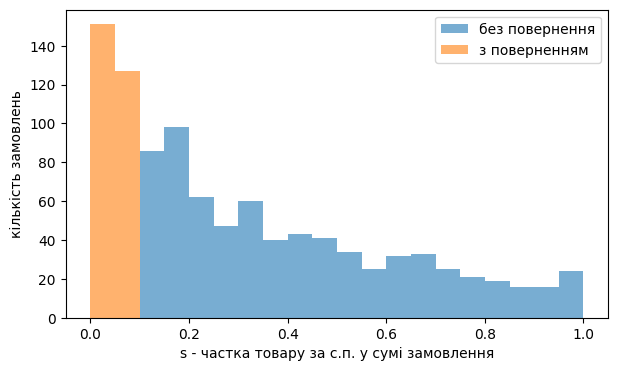

In [55]:
fine = np.linspace(0, 1, 21)
plt.figure(figsize=(7, 4))
plt.hist(share[~back], bins=fine, alpha=0.6, label="без повернення")
plt.hist(share[back], bins=fine, alpha=0.6, label="з поверненням")
plt.xlabel("s - частка товару за с.п. у сумі замовлення")
plt.ylabel("кількість замовлень")
plt.legend()
plt.show()

Перевіримо залежність прямим підрахунком. Якщо найбільше $s$ серед повернених менше за найменше $s$ серед неповернених, групи не перетинаються. Далі подивимось на таблицю «$s<0.1$ / повернення» і оцінимо, наскільки така картина ймовірна за гіпотези $H_0$: повернення не залежить від $s$. За $H_0$ «повернені» 278 замовлень - довільна підмножина з 1000, і ймовірність того, що це в точності 278 замовлень з найменшим $s$, дорівнює $1/C_{1000}^{278}$.

In [56]:
from math import comb

print("max s серед повернених:      ", round(share[back].max(), 5))
print("min s серед неповернених:    ", round(share[~back].min(), 5))

small = share < 0.1
print("\n                s < 0.1   s >= 0.1")
print("повернено      ", (back & small).sum(), "      ", (back & ~small).sum())
print("не повернено   ", (~back & small).sum(), "      ", (~back & ~small).sum())

m = back.sum()
print(f"\nймовірність за H0: 1/C({N},{m}) = {1 / comb(N, m):.3e}")

print("\nвитрати на доставку через повернення:", back.sum() * 20, "грн із", N, "замовлень")
print("середня сума замовлення, грн:  повернені", round(orders.loc[back, "total"].mean(), 2),
      "  решта", round(orders.loc[~back, "total"].mean(), 2))
print("середня ціна с.п. товару, грн: повернені", round(sp[back].mean(), 2),
      "  решта", round(sp[~back].mean(), 2))

max s серед повернених:       0.09902
min s серед неповернених:     0.10009

                s < 0.1   s >= 0.1
повернено       278        0
не повернено    0        722

ймовірність за H0: 1/C(1000,278) = 7.225e-256

витрати на доставку через повернення: 5560 грн із 1000 замовлень
середня сума замовлення, грн:  повернені 174.71   решта 113.46
середня ціна с.п. товару, грн: повернені 8.2   решта 40.22


**Результат.** Повернення визначаються часткою с.п., причому майже детерміновано:
- серед повернених замовлень $s$ в середньому $\approx0.05$, найбільше значення $0.099$; серед решти в середньому $\approx0.42$, найменше $0.100$ - групи не перетинаються;
- у інтервалі $(0;\,0.1]$ повертають усі замовлення, в інших інтервалах - жодного;
- у таблиці немає ні замовлень із $s<0.1$ без повернення, ні повернень із $s\ge0.1$; за $H_0$ це мало б ймовірність $1/C_{1000}^{278}\approx7\cdot10^{-256}$, тож $H_0$ відхиляємо.

Тобто товар за с.п. повертають тоді й лише тоді, коли він складає менше 10% суми замовлення. Кореляція не доводить умислу, але картина відповідає підозрі: до дорогого замовлення (в середньому 175 грн проти 113 грн) додають дешевий акційний товар (8 грн проти 40 грн), отримують безкоштовну доставку й повертають лише його. За розділом 1 так роблять близько 28% замовлень (інтервал рівня 0.95: 25%-31%), магазин через це недоотримав приблизно 5560 грн за доставку.

## 5. Задача варіанта 3

Чи можна лише за вибіркою $R_i=\xi_i/\eta_i$ оцінити $\lambda$ і $k$, якщо $\xi_i\sim Exp(\lambda)$, $\eta_i\sim Exp(\lambda k)$ незалежні?

**Розподіл $R$.** Умовимо на $\eta=y$: $P(\xi>ry)=e^{-\lambda ry}$, тому
$$P(R>r)=\int_0^\infty\lambda k\,e^{-\lambda ky}e^{-\lambda ry}\,dy=\frac{k}{k+r},\qquad F_R(r)=\frac{r}{k+r}.$$

**$\lambda$ у формулі немає.** Якщо помножити $\xi$ та $\eta$ на $c>0$ (інші одиниці виміру), то $\lambda$ стане $\lambda/c$, а $k$ і $R$ не зміняться. Тому пари $(\lambda,k)$ та $(\lambda/c,k)$ дають вибірки з однаковим розподілом, і $\lambda$ за $R$ оцінити неможливо.

**Оцінка $k$.** Метод моментів за середнім не працює, бо $ER=\infty$. Проте $F_R(k)=\frac12$, тобто $k$ - медіана $R$, і $\hat k=\text{med}(R_1,\dots,R_N)$ - консистентна оцінка (щільність у точці $k$ додатна: $f_R(k)=\frac1{4k}$). Точніша - ОМП: з $\ell(k)=N\ln k-2\sum\ln(k+R_i)$ рівняння $\frac Nk-2\sum\frac1{k+R_i}=0$ розв'язуємо чисельно; інформація Фішера $I(k)=\frac1{3k^2}$, тому $SE=k\sqrt{3/N}$.

In [57]:
ratio = other / sp
k_med = np.median(ratio)

def score(k):
    return N / k - 2 * np.sum(1 / (k + ratio))

left, right = 1e-3, 1e3
for _ in range(100):
    mid = (left + right) / 2
    if score(mid) > 0:
        left = mid
    else:
        right = mid
k_mle = (left + right) / 2
se_k = k_mle * np.sqrt(3 / N)

print(f"медіана: {k_med:.4f}\nОМП:     {k_mle:.4f}   (SE = {se_k:.4f})\nk за розділом 3: {k_means:.4f}")
show_intervals(k_mle, se_k)

медіана: 3.2894
ОМП:     3.2085   (SE = 0.1757)
k за розділом 3: 3.1659
рівень 0.95: від 2.8640 до 3.5529
рівень 0.99: від 2.7558 до 3.6612


**Відповідь.** За вибіркою $\xi_i/\eta_i$ можна оцінити лише $k$; $\lambda$ оцінити неможливо, бо розподіл $R$ від нього не залежить. Для $k$ маємо $\hat k_{med}\approx3.29$ та $\hat k_{ОМП}\approx3.21$ з 95% інтервалом $[2.86;\ 3.55]$, що узгоджується з $\hat k\approx3.17$ із розділу 3 (там $\xi$ та $\eta$ відомі окремо).